<a href="https://colab.research.google.com/github/Siva-p-11/ML-assiments/blob/main/Clustering_and_mixture_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip -q install pandas numpy scipy scikit-learn matplotlib seaborn


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

URL = (
    "https://huggingface.co/spaces/febbrri/supply-chain/"
    "resolve/main/supply_chain_data.csv"
)

df = pd.read_csv(URL)

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset dimensions: (100, 24)

Column names:
['Product type', 'SKU', 'Price', 'Availability', 'Number of products sold', 'Revenue generated', 'Customer demographics', 'Stock levels', 'Lead times', 'Order quantities', 'Shipping times', 'Shipping carriers', 'Shipping costs', 'Supplier name', 'Location', 'Lead time', 'Production volumes', 'Manufacturing lead time', 'Manufacturing costs', 'Inspection results', 'Defect rates', 'Transportation modes', 'Routes', 'Costs']


,Product type,SKU,Price,Availability,Number of products sold,Revenue generated,Customer demographics,Stock levels,Lead times,Order quantities,...,Location,Lead time,Production volumes,Manufacturing lead time,Manufacturing costs,Inspection results,Defect rates,Transportation modes,Routes,Costs
0,haircare,SKU0,69.808006,55,802,8661.996792,Non-binary,58,7,96,...,Mumbai,29,215,29,46.279879,Pending,0.226410,Road,Route B,187.752075
1,skincare,SKU1,14.843523,95,736,7460.900065,Female,53,30,37,...,Mumbai,23,517,30,33.616769,Pending,4.854068,Road,Route B,503.065579
2,haircare,SKU2,11.319683,34,8,9577.749626,Unknown,1,10,88,...,Mumbai,12,971,27,30.688019,Pending,4.580593,Air,Route C,141.920282
3,skincare,SKU3,61.163343,68,83,7766.836426,Non-binary,23,13,59,...,Kolkata,24,937,18,35.624741,Fail,4.746649,Rail,Route A,254.776159
4,skincare,SKU4,4.805496,26,871,2686.505152,Non-binary,5,3,56,...,Delhi,5,414,3,92.065161,Fail,3.145580,Air,Route A,923.440632


In [3]:

# Inspect data quality
print("Missing values:")
print(df[[
    "Shipping times",
    "Order quantities",
    "Manufacturing lead time"
]].isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Select assignment-relevant features
feature_columns = [
    "Shipping times",
    "Order quantities",
    "Manufacturing lead time"
]

data = df[["SKU"] + feature_columns].copy()

for col in feature_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=feature_columns).reset_index(drop=True)

# Each row represents a product/SKU operational profile
print("Usable records:", len(data))
display(data.head())

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(data[feature_columns])

print("Scaled feature matrix:", X_scaled.shape)


Missing values:
Shipping times             0
Order quantities           0
Manufacturing lead time    0
dtype: int64

Duplicate rows: 0
Usable records: 100


,SKU,Shipping times,Order quantities,Manufacturing lead time
0,SKU0,4,96,29
1,SKU1,2,37,30
2,SKU2,2,88,27
3,SKU3,6,59,18
4,SKU4,8,56,3


Scaled feature matrix: (100, 3)


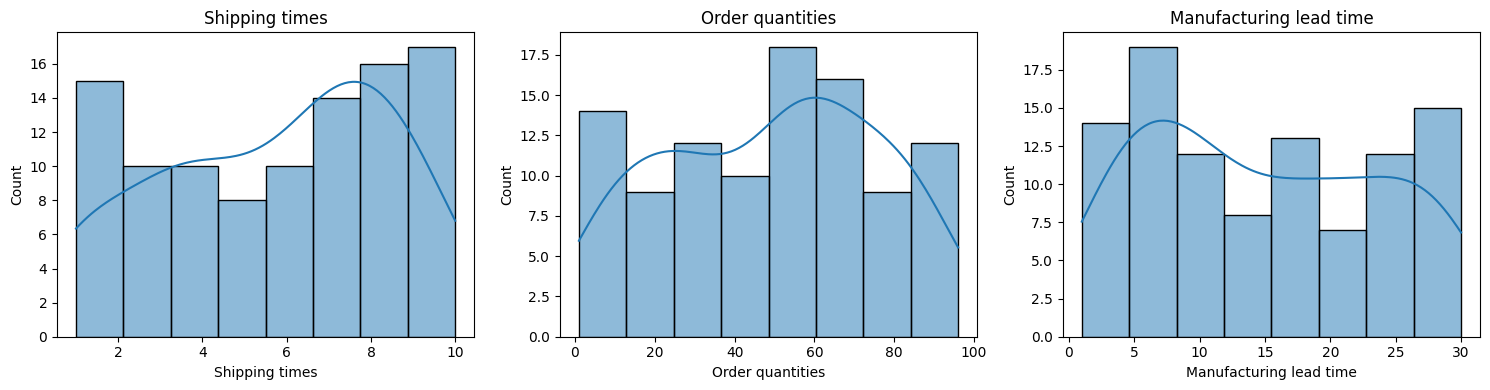

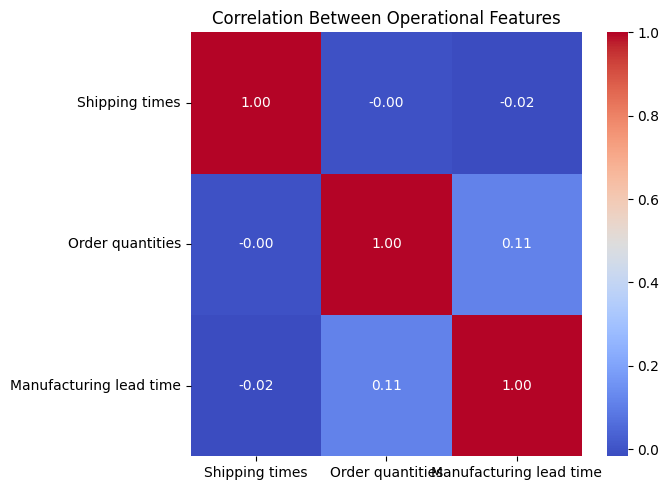

In [4]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(feature_columns):
    sns.histplot(data[col], kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(
    data[feature_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Operational Features")
plt.tight_layout()
plt.show()


Explained variance ratio:
PC1: 0.3713 (37.13%)
PC2: 0.3331 (33.31%)
PC3: 0.2956 (29.56%)
Total variance retained by 2 PCs: 70.44 %


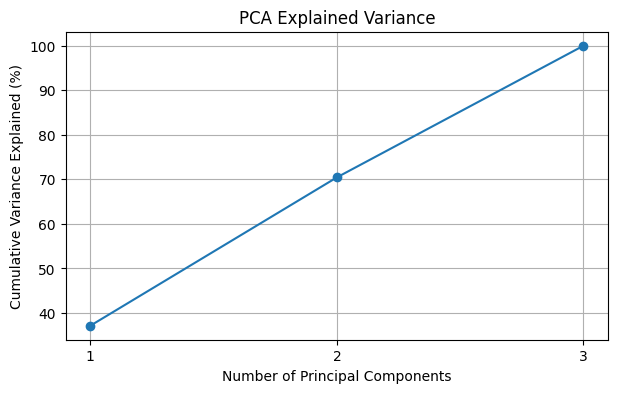

Representations:
Original_3D (100, 3)
PCA_2D (100, 2)
PCA_3D (100, 3)


In [5]:

from sklearn.decomposition import PCA

pca_full = PCA(n_components=3)
X_pca_full = pca_full.fit_transform(X_scaled)

print("Explained variance ratio:")
for i, ratio in enumerate(pca_full.explained_variance_ratio_, 1):
    print(f"PC{i}: {ratio:.4f} ({ratio * 100:.2f}%)")

print(
    "Total variance retained by 2 PCs:",
    round(pca_full.explained_variance_ratio_[:2].sum() * 100, 2),
    "%"
)

plt.figure(figsize=(7, 4))
plt.plot(
    [1, 2, 3],
    np.cumsum(pca_full.explained_variance_ratio_) * 100,
    marker="o"
)
plt.xticks([1, 2, 3])
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Variance Explained (%)")
plt.title("PCA Explained Variance")
plt.grid(True)
plt.show()

# Different representations for the clustering experiment
spaces = {
    "Original_3D": X_scaled,
    "PCA_2D": X_pca_full[:, :2],
    "PCA_3D": X_pca_full[:, :3]
}

print("Representations:")
for name, matrix in spaces.items():
    print(name, matrix.shape)


In [6]:

from scipy.spatial.distance import pdist, squareform

def calculate_dunn_index(X, labels):
    X = np.asarray(X)
    labels = np.asarray(labels)
    unique_clusters = np.unique(labels)

    if len(unique_clusters) < 2:
        return np.nan

    distances = squareform(pdist(X, metric="euclidean"))

    max_diameter = 0.0
    min_separation = np.inf

    for i, cluster_a in enumerate(unique_clusters):
        idx_a = np.where(labels == cluster_a)[0]

        # Maximum within-cluster distance
        if len(idx_a) > 1:
            within = distances[np.ix_(idx_a, idx_a)]
            max_diameter = max(max_diameter, within.max())

        # Minimum distance between this cluster and all later clusters
        for cluster_b in unique_clusters[i + 1:]:
            idx_b = np.where(labels == cluster_b)[0]
            between = distances[np.ix_(idx_a, idx_b)]
            min_separation = min(min_separation, between.min())

    if max_diameter == 0:
        return np.nan

    return min_separation / max_diameter


In [7]:

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
cluster_counts = [2, 3, 4, 5]

results = []
saved_labels = {}

for space_name, X_space in spaces.items():

    for k in cluster_counts:

        models = {
            "K-Means": KMeans(
                n_clusters=k,
                n_init=10,
                random_state=RANDOM_STATE
            ),
            "GMM": GaussianMixture(
                n_components=k,
                covariance_type="full",
                n_init=3,
                reg_covar=1e-5,
                random_state=RANDOM_STATE
            ),
            "Hierarchical": AgglomerativeClustering(
                n_clusters=k,
                linkage="ward"
            )
        }

        for algorithm, model in models.items():

            if algorithm == "GMM":
                model.fit(X_space)
                labels = model.predict(X_space)
            else:
                labels = model.fit_predict(X_space)

            # Validity metrics
            silhouette = silhouette_score(X_space, labels)
            dunn = calculate_dunn_index(X_space, labels)

            results.append({
                "Representation": space_name,
                "Dimensions": X_space.shape[1],
                "Algorithm": algorithm,
                "K": k,
                "Silhouette Score": silhouette,
                "Dunn Index": dunn
            })

            saved_labels[(space_name, algorithm, k)] = labels

results_df = pd.DataFrame(results)

print("All experiments completed:", len(results_df))
display(
    results_df.sort_values(
        "Silhouette Score", ascending=False
    ).round(4)
)


All experiments completed: 36


,Representation,Dimensions,Algorithm,K,Silhouette Score,Dunn Index
16,PCA_2D,2,GMM,3,0.4015,0.0754
18,PCA_2D,2,K-Means,4,0.3999,0.0655
15,PCA_2D,2,K-Means,3,0.3986,0.0590
17,PCA_2D,2,Hierarchical,3,0.3680,0.0745
19,PCA_2D,2,GMM,4,0.3589,0.0663
22,PCA_2D,2,GMM,5,0.3570,0.0692
21,PCA_2D,2,K-Means,5,0.3545,0.0812
13,PCA_2D,2,GMM,2,0.3523,0.0158
20,PCA_2D,2,Hierarchical,4,0.3452,0.0747
23,PCA_2D,2,Hierarchical,5,0.3294,0.0747


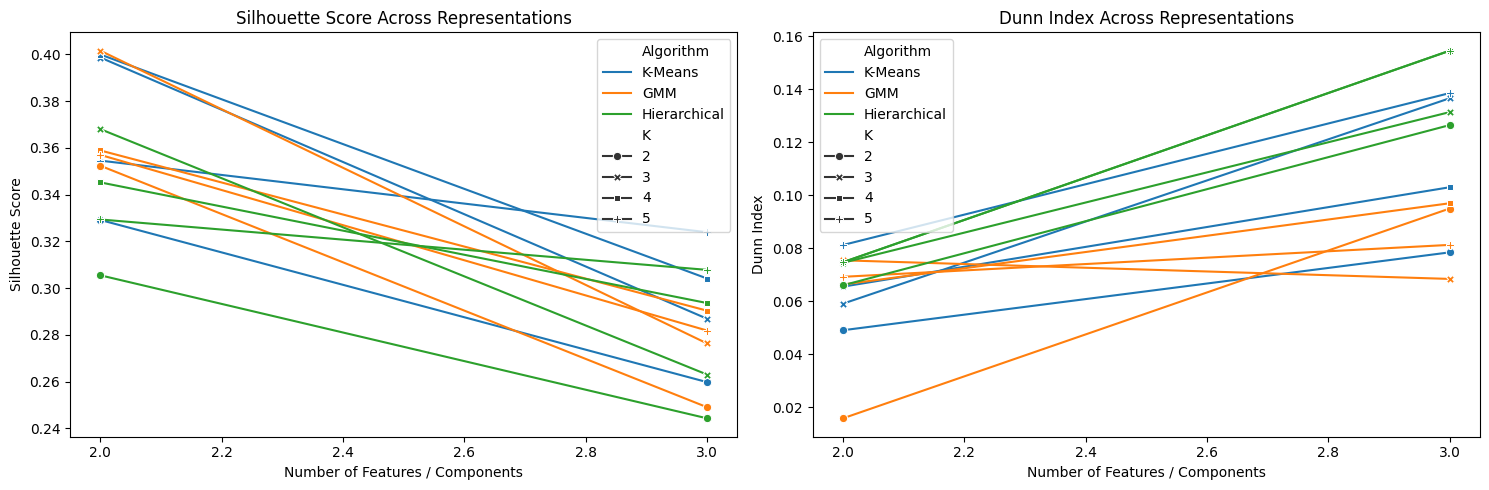

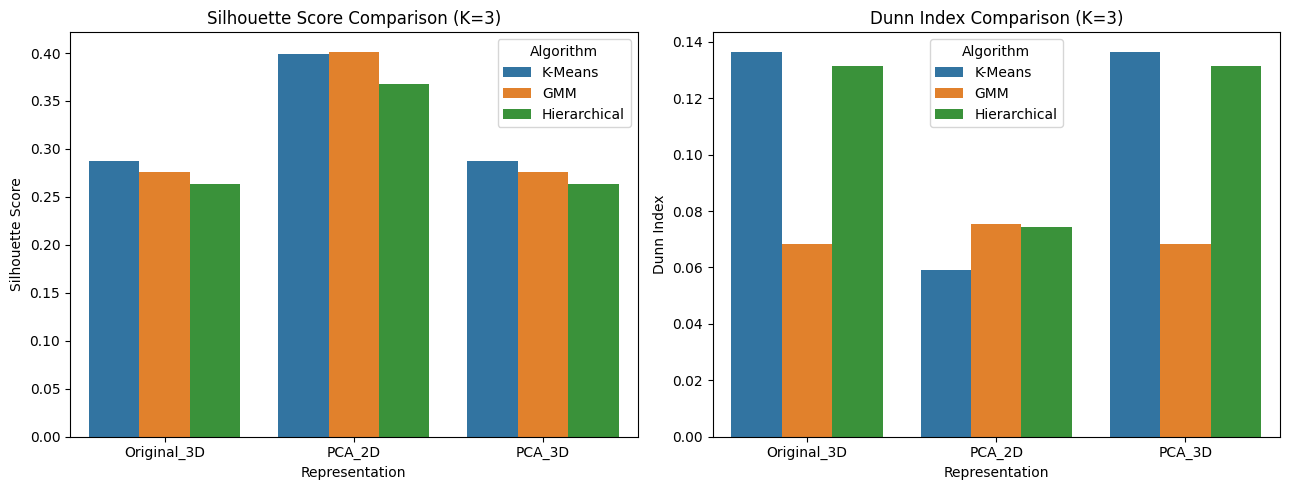

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(
    data=results_df,
    x="Dimensions",
    y="Silhouette Score",
    hue="Algorithm",
    style="K",
    markers=True,
    dashes=False,
    ax=axes[0]
)
axes[0].set_title("Silhouette Score Across Representations")
axes[0].set_xlabel("Number of Features / Components")

sns.lineplot(
    data=results_df,
    x="Dimensions",
    y="Dunn Index",
    hue="Algorithm",
    style="K",
    markers=True,
    dashes=False,
    ax=axes[1]
)
axes[1].set_title("Dunn Index Across Representations")
axes[1].set_xlabel("Number of Features / Components")

plt.tight_layout()
plt.show()

# Compare algorithms at K=3
comparison = results_df[results_df["K"] == 3]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=comparison,
    x="Representation",
    y="Silhouette Score",
    hue="Algorithm",
    ax=axes[0]
)
axes[0].set_title("Silhouette Score Comparison (K=3)")

sns.barplot(
    data=comparison,
    x="Representation",
    y="Dunn Index",
    hue="Algorithm",
    ax=axes[1]
)
axes[1].set_title("Dunn Index Comparison (K=3)")

plt.tight_layout()
plt.show()


Best experiment based on Silhouette Score
Representation: PCA_2D
Algorithm: GMM
Number of clusters: 3
Silhouette Score: 0.4015
Dunn Index: 0.0754

Cluster sizes:


,Number of SKUs
Cluster,
0,41
1,19
2,40



Cluster operational profiles:


,Shipping times,Order quantities,Manufacturing lead time
Cluster,,,
0,5.37,29.88,8.51
1,2.16,64.00,22.63
2,7.85,62.02,17.45


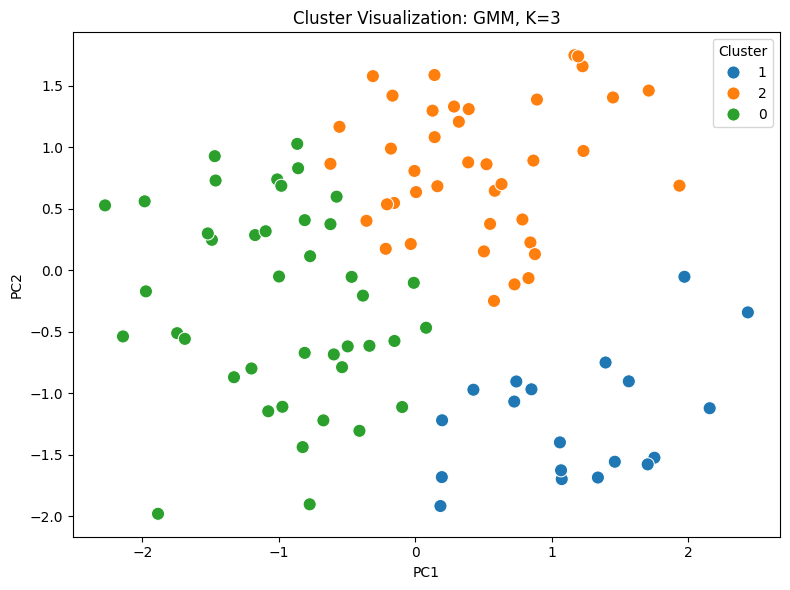

,SKU,Shipping times,Order quantities,Manufacturing lead time,Cluster
0,SKU0,4,96,29,1
1,SKU1,2,37,30,1
2,SKU2,2,88,27,1
3,SKU3,6,59,18,2
4,SKU4,8,56,3,0
5,SKU5,3,66,17,1
6,SKU6,8,58,24,2
7,SKU7,1,11,1,0
8,SKU8,7,15,8,0
9,SKU9,1,83,23,1


In [9]:

best_row = results_df.loc[
    results_df["Silhouette Score"].idxmax()
]

best_space = best_row["Representation"]
best_algorithm = best_row["Algorithm"]
best_k = int(best_row["K"])

print("Best experiment based on Silhouette Score")
print("Representation:", best_space)
print("Algorithm:", best_algorithm)
print("Number of clusters:", best_k)
print("Silhouette Score:", round(best_row["Silhouette Score"], 4))
print("Dunn Index:", round(best_row["Dunn Index"], 4))

# Attach cluster labels to the original records
clustered_data = data.copy()
clustered_data["Cluster"] = saved_labels[
    (best_space, best_algorithm, best_k)
]

print("\nCluster sizes:")
display(
    clustered_data["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Number of SKUs")
    .to_frame()
)

print("\nCluster operational profiles:")
cluster_summary = clustered_data.groupby("Cluster")[
    feature_columns
].mean().round(2)

display(cluster_summary)

# Visualize clusters in two-dimensional PCA space
pca_2d = pd.DataFrame({
    "PC1": X_pca_full[:, 0],
    "PC2": X_pca_full[:, 1],
    "Cluster": clustered_data["Cluster"].astype(str)
})

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_2d,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=90
)
plt.title(
    f"Cluster Visualization: {best_algorithm}, K={best_k}"
)
plt.tight_layout()
plt.show()

display(clustered_data.head(10))


In [10]:

from google.colab import files
import zipfile

results_df.to_csv("clustering_validity_results.csv", index=False)
clustered_data.to_csv("cluster_assignments.csv", index=False)
cluster_summary.to_csv("cluster_profile_summary.csv")

with zipfile.ZipFile(
    "supply_chain_clustering_results.zip", "w"
) as z:
    z.write("clustering_validity_results.csv")
    z.write("cluster_assignments.csv")
    z.write("cluster_profile_summary.csv")

files.download("supply_chain_clustering_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

best_silhouette = best_row["Silhouette Score"]
best_dunn = best_row["Dunn Index"]

print("EXPERIMENTAL CONCLUSION")
print("-" * 45)

print(
    f"The highest Silhouette Score was {best_silhouette:.4f}, "
    f"achieved by {best_algorithm} using {best_space} "
    f"with K={best_k}."
)

print(f"The corresponding Dunn Index was {best_dunn:.4f}.")

if best_silhouette > 0.5:
    print("The selected solution shows reasonably strong cluster separation.")
elif best_silhouette > 0.25:
    print("The selected solution shows moderate cluster structure.")
else:
    print("The selected solution has weak separation; clusters overlap.")

print(
    "\nThe clusters describe product-level supply-chain operational "
    "profiles. Shipping time and manufacturing lead time are used as "
    "proxies; they are not direct measurements of delivery delay duration "
    "or warehouse handling time."
)


EXPERIMENTAL CONCLUSION
---------------------------------------------
The highest Silhouette Score was 0.4015, achieved by GMM using PCA_2D with K=3.
The corresponding Dunn Index was 0.0754.
The selected solution shows moderate cluster structure.

The clusters describe product-level supply-chain operational profiles. Shipping time and manufacturing lead time are used as proxies; they are not direct measurements of delivery delay duration or warehouse handling time.
